# Setup Environment, Training, & Validasi Model YOLOv8

## Setup Environment & Verifikasi GPU

In [5]:
# 1.1.1 Install dependencies utama
!pip install -q ultralytics opencv-python pandas matplotlib

# 1.1.2 Cek kesiapan GPU & versi Ultralytics
import torch
import ultralytics

print(f"Ultralytics Version : {ultralytics.__version__}")
print(f"PyTorch Version     : {torch.__version__}")
print(f"CUDA Available      : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU Device Name     : {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: GPU tidak terdeteksi. Proses training mungkin akan berjalan lambat.")

Ultralytics Version : 8.4.174
PyTorch Version     : 2.11.0+cu130
CUDA Available      : True
GPU Device Name     : Tesla T4


## Pelatihan Model (Training)

In [6]:
import zipfile

zip_path = "/content/road_preprocessed.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Berhasil diekstrak tanpa mengubah nama.")

Berhasil diekstrak tanpa mengubah nama.


In [7]:
import os
from ultralytics import YOLO

# 1.2.1 Inisialisasi model pretrained YOLOv8 Nano
model = YOLO("yolov8n.pt")

# 1.2.2 Set path file YAML sesuai konfigurasi kamu
YAML_PATH = "/content/road_preprocessed/data.yaml"

# 1.2.3 Eksekusi Training
results = model.train(
    data=YAML_PATH,
    epochs=50,
    imgsz=640,
    batch=16,
    workers=4,
    name="road_damage_yolov8",
    project="runs/detect",
    exist_ok=True,
    verbose=True
)

print("Training Selesai! Weight terbaik tersimpan di: runs/detect/road_damage_yolov8/weights/best.pt")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/road_preprocessed/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=road_damage_yolov8, nbs=64, nms=None, opset=None, opti

## Evaluasi & Validasi Model pada Test Set

In [9]:
# 1.3.1 Load weight terbaik hasil training
best_model_path = "runs/detect/runs/detect/road_damage_yolov8/weights/best.pt"
trained_model = YOLO(best_model_path)

# 1.3.2 Evaluasi pada Test Set (menggunakan data dari YAML)
metrics = trained_model.val(split="test")

# 1.3.3 Tampilkan performa deteksi
print("\n=== HASIL EVALUASI MODEL (TEST SET) ===")
print(f"mAP50-95 : {metrics.box.map:.4f}")
print(f"mAP50    : {metrics.box.map50:.4f}")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall   : {metrics.box.mr:.4f}")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2366.6±823.6 MB/s, size: 95.5 KB)
val: Scanning /content/road_preprocessed/test/labels... 199 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 199/199 1.9Kit/s 0.1s
val: New cache created: /content/road_preprocessed/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 4.4it/s 3.0s
                   all        199        491      0.587      0.504      0.516      0.226
               pothole         81        141      0.527      0.447      0.426       0.16
                 crack        141        257      0.467      0.393      0.381      0.148
               manhole         76         93      0.767      0.673      0.742      0.369
Speed: 1.7ms preprocess, 3.9ms inference, 0.0ms loss, 2.0ms postpr

## Sanity Check / Tes Inferensi Visual Sederhana


image 1/1 /content/road_preprocessed/test/images/vlcsnap-2025-02-26-20h33m48s935.jpg: 384x640 1 manhole, 8.4ms
Speed: 0.9ms preprocess, 8.4ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)


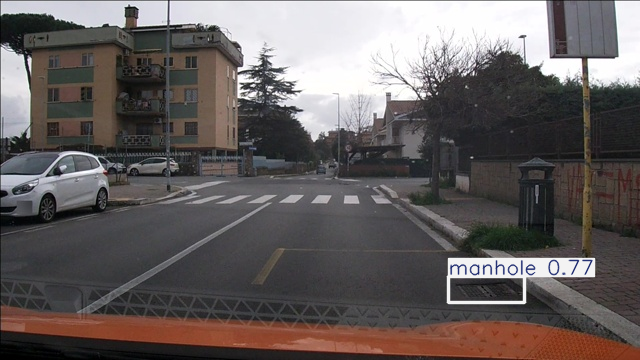

Sampel diuji: /content/road_preprocessed/test/images/vlcsnap-2025-02-26-20h33m48s935.jpg


In [10]:
import cv2
import glob
from google.colab.patches import cv2_imshow # Hapus / sesuaikan jika tidak di Colab

# 1.4.1 Ambil 1 sampel gambar dari folder test
test_images = glob.glob("/content/road_preprocessed/test/images/*.jpg")

if test_images:
    sample_img_path = test_images[0]

    # 1.4.2 Prediksi dengan model
    results = trained_model(sample_img_path)

    # 1.4.3 Plot hasil deteksi ke gambar
    annotated_frame = results[0].plot()

    # 1.4.4 Tampilkan hasil visual
    cv2_imshow(annotated_frame)
    print(f"Sampel diuji: {sample_img_path}")
else:
    print("Tidak ditemukan file .jpg di folder test/images. Pastikan path gambar benar.")

# Pembangunan Modul Feature Extractor & Scoring Engine

## Inisialisasi Konfigurasi Bobot & Threshold

In [11]:
# 2.1.1 Deklarasi Matriks Bobot Dampak Kerusakan (Severity Weight)
# Semakin besar nilainya, semakin besar penalti terhadap skor jalan.
CLASS_WEIGHTS = {
    0: 3.0,  # Pothole (Lubang) -> Dampak tinggi / bahaya
    1: 1.5,  # Crack (Retak)   -> Dampak sedang
    2: 0.0   # Manhole         -> Dampak nol (fitur umum jalan, bukan kerusakan)
}

# 2.1.2 Confidence Threshold
# Hanya deteksi dengan tingkat kepastian >= 0.25 yang diproses ke scoring engine
CONF_THRESHOLD = 0.25

## Modul Feature Extractor (Spasial & Luas Bounding Box)

In [12]:
import numpy as np

def extract_spatial_features(yolo_result, img_shape):
    """
    Mengekstrak fitur spasial dari bounding box hasil inferensi YOLOv8.
    """
    img_h, img_w = img_shape[:2]
    total_img_area = img_h * img_w

    extracted_objects = []
    total_raw_damage_area = 0.0
    total_weighted_damage_area = 0.0

    boxes = yolo_result.boxes
    if boxes is not None and len(boxes) > 0:
        for box in boxes:
            conf = float(box.conf[0].item())
            if conf < CONF_THRESHOLD:
                continue

            cls_id = int(box.cls[0].item())
            cls_name = yolo_result.names[cls_id]

            # Koordinat Bounding Box [x1, y1, x2, y2]
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            box_w = max(0, x2 - x1)
            box_h = max(0, y2 - y1)
            box_area = box_w * box_h

            # Rasio luas bounding box terhadap total luas citra (%)
            area_ratio = (box_area / total_img_area) * 100.0

            # Bobot kelas
            weight = CLASS_WEIGHTS.get(cls_id, 1.0)

            # Manhole (ID: 2) diabaikan dari perhitungan akumulasi kerusakan
            if cls_id != 2:
                total_raw_damage_area += box_area
                total_weighted_damage_area += (box_area * weight)

            extracted_objects.append({
                "class_id": cls_id,
                "class_name": cls_name,
                "confidence": round(conf, 4),
                "bbox": [round(x1, 1), round(y1, 1), round(x2, 1), round(y2, 1)],
                "box_area_px": round(box_area, 2),
                "area_percentage": round(area_ratio, 4),
                "severity_weight": weight
            })

    raw_damage_percentage = (total_raw_damage_area / total_img_area) * 100.0
    weighted_damage_percentage = (total_weighted_damage_area / total_img_area) * 100.0

    return {
        "extracted_objects": extracted_objects,
        "total_img_area_px": total_img_area,
        "raw_damage_percentage": round(raw_damage_percentage, 4),
        "weighted_damage_percentage": round(weighted_damage_percentage, 4)
    }

## Modul Scoring Engine (Perhitungan Indeks Kondisi)

In [13]:
def calculate_road_score(spatial_data):
    """
    Menghitung skor kondisi jalan skala 0-100 dan menentukan status kelayakan.
    - 100: Jalan Sangat Baik / Mulus
    - 0  : Jalan Hancur Total
    """
    weighted_ratio = spatial_data["weighted_damage_percentage"]

    # Scaling Factor: Pengali untuk menyesuaikan rasio luas ke penalti skor
    # Mengingat bounding box merepresentasikan area yang menutupi kerusakan
    SCALING_FACTOR = 12.0

    # Hitung total penalti (maksimal 100)
    score_penalty = min(100.0, weighted_ratio * SCALING_FACTOR)

    # Skor kondisi jalan
    road_score = max(0.0, 100.0 - score_penalty)

    # Kategorisasi kondisi jalan berdasarkan kriteria standar dinas teknis
    if road_score >= 85.0:
        status = "Baik / Kerusakan Sangat Ringan"
        action = "Pemeliharaan Rutin"
    elif road_score >= 65.0:
        status = "Rusak Ringan"
        action = "Pemeliharaan Berkala"
    elif road_score >= 45.0:
        status = "Rusak Sedang"
        action = "Rehabilitasi Jalan"
    else:
        status = "Rusak Berat"
        action = "Rekonstruksi Total"

    return {
        "road_score": round(road_score, 2),
        "score_penalty": round(score_penalty, 2),
        "status": status,
        "recommended_action": action
    }

## Pengujian Integrasi Tahap 2

In [16]:
# Tes integrasi fungsi Feature Extractor & Scoring Engine menggunakan model dari Tahap 1
import glob
from ultralytics import YOLO

# 2.4.1 Load model (mencari path best.pt secara otomatis agar tidak keliru jalur)
found_weights = glob.glob("runs/detect/**/weights/best.pt", recursive=True)
if found_weights:
    trained_model = YOLO(found_weights[-1])
else:
    raise FileNotFoundError("File best.pt tidak ditemukan. Pastikan proses training sudah selesai.")

# 2.4.2 Ambil gambar pertama secara otomatis dari folder test
test_images = glob.glob("/content/road_preprocessed/test/images/*.jpg") + \
              glob.glob("/content/road_preprocessed/test/images/*.png") + \
              glob.glob("/content/road_preprocessed/test/images/*.jpeg")

if test_images:
    sample_image = test_images[0]
    print(f"Menggunakan sampel gambar: {sample_image}")

    # Jalankan inferensi pada 1 sampel gambar test
    results = trained_model(sample_image)[0]

    # 2.4.3 Ekstraksi Fitur
    spatial_features = extract_spatial_features(results, results.orig_shape)

    # 2.4.4 Hitung Skor
    scoring_result = calculate_road_score(spatial_features)

    print("\n=== HASIL EXTRACTION & SCORING ===")
    print("Objects Detected :", len(spatial_features["extracted_objects"]))
    print("Raw Damage Area  :", spatial_features["raw_damage_percentage"], "%")
    print("Road Score       :", scoring_result["road_score"], "/ 100")
    print("Status           :", scoring_result["status"])
    print("Rekomendasi      :", scoring_result["recommended_action"])
else:
    print("Error: Tidak ditemukan gambar di folder /content/road_preprocessed/test/images/")

Menggunakan sampel gambar: /content/road_preprocessed/test/images/vlcsnap-2025-02-26-20h33m48s935.jpg

image 1/1 /content/road_preprocessed/test/images/vlcsnap-2025-02-26-20h33m48s935.jpg: 384x640 1 manhole, 8.4ms
Speed: 1.3ms preprocess, 8.4ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)

=== HASIL EXTRACTION & SCORING ===
Objects Detected : 1
Raw Damage Area  : 0.0 %
Road Score       : 100.0 / 100
Status           : Baik / Kerusakan Sangat Ringan
Rekomendasi      : Pemeliharaan Rutin


# Pembuatan Pipeline Integrasi & Ekspor Laporan Output

## Pipeline Pemrosesan Tunggal (Gambar ke Dict Result)

In [17]:
import cv2
import os
import json
import pandas as pd
from ultralytics import YOLO

def analyze_single_image(image_path, model, output_vis_dir=None):
    """
    Memproses 1 citra: Inferensi -> Feature Extraction -> Scoring -> Visualisasi
    """
    # Read Image
    img = cv2.imread(image_path)
    if img is None:
        return None

    # 1. Inferensi Model
    results = model(image_path, verbose=False)[0]

    # 2. Extract Features (Fungsi dari Tahap 2)
    spatial_data = extract_spatial_features(results, img.shape)

    # 3. Calculate Score (Fungsi dari Tahap 2)
    score_data = calculate_road_score(spatial_data)

    # 4. Simpan Gambar Hasil Visualisasi (Annotated Image)
    filename = os.path.basename(image_path)
    if output_vis_dir:
        os.makedirs(output_vis_dir, exist_ok=True)
        annotated_frame = results.plot()

        # Tambahkan teks Skor pada Gambar
        score_text = f"Score: {score_data['road_score']}/100 ({score_data['status']})"
        cv2.putText(annotated_frame, score_text, (20, 40),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 255), 2)

        save_path = os.path.join(output_vis_dir, f"result_{filename}")
        cv2.imwrite(save_path, annotated_frame)

    # Ringkasan per File
    report = {
        "file_name": filename,
        "image_path": image_path,
        "total_objects": len(spatial_data["extracted_objects"]),
        "raw_damage_percentage": spatial_data["raw_damage_percentage"],
        "weighted_damage_percentage": spatial_data["weighted_damage_percentage"],
        "road_score": score_data["road_score"],
        "score_penalty": score_data["score_penalty"],
        "status": score_data["status"],
        "recommended_action": score_data["recommended_action"],
        "detections_detail": spatial_data["extracted_objects"]
    }

    return report

## Batch Pipeline & Ekspor Otomatis (JSON & CSV)

In [27]:
import glob

def run_full_analysis_pipeline(input_folder, model_path, output_dir="output_reports"):
    """
    Memproses seluruh gambar dalam folder dan mengekspor laporan ke JSON & CSV.
    """
    os.makedirs(output_dir, exist_ok=True)
    vis_dir = os.path.join(output_dir, "annotated_images")

    # Load Trained Model
    model = YOLO(model_path)

    # Ambil semua file gambar (.jpg, .png, .jpeg)
    image_extensions = ["*.jpg", "*.jpeg", "*.png"]
    image_paths = []
    for ext in image_extensions:
        image_paths.extend(glob.glob(os.path.join(input_folder, ext)))

    print(f"Mulai memproses {len(image_paths)} gambar dari folder: {input_folder}")

    all_reports = []
    summary_list = []

    for path in image_paths:
        report = analyze_single_image(path, model, output_vis_dir=vis_dir)
        if report:
            all_reports.append(report)

            # Buat baris ringkasan untuk CSV (tanpa detail koordinat)
            summary_baris = {
                "File Name": report["file_name"],
                "Total Objek Rusak": report["total_objects"],
                "Luas Kerusakan (%)": report["raw_damage_percentage"],
                "Skor Kondisi Jalan": report["road_score"],
                "Penalti Skor": report["score_penalty"],
                "Status": report["status"],
                "Rekomendasi Tindakan": report["recommended_action"]
            }
            summary_list.append(summary_baris)

    # 1. Ekspor ke JSON (Detail Lengkap beserta koordinat Bounding Box)
    json_output_path = os.path.join(output_dir, "laporan_kerusakan_jalan.json")
    with open(json_output_path, "w") as f:
        json.dump(all_reports, f, indent=4)

    # 2. Ekspor ke CSV (Tabel Ringkasan untuk Analisis / Power BI / Excel)
    csv_output_path = os.path.join(output_dir, "laporan_kerusakan_jalan.csv")
    df = pd.DataFrame(summary_list)
    df.to_csv(csv_output_path, index=False)

    print("\n=== PIPELINE SELESAI DITERAPKAN ===")
    print(f"1. Laporan JSON : {json_output_path}")
    print(f"2. Laporan CSV  : {csv_output_path}")
    print(f"3. Foto Hasil   : {vis_dir}")

    return df

## Eksekusi Batch Pipeline pada Folder Test

In [28]:
# Eksekusi Pipeline menggunakan data folder test dari Tahap 1
TEST_FOLDER = "/content/road_preprocessed/test/images"
MODEL_WEIGHTS = "runs/detect/runs/detect/road_damage_yolov8/weights/best.pt"

# Jalankan Pipeline
df_report = run_full_analysis_pipeline(
    input_folder=TEST_FOLDER,
    model_path=MODEL_WEIGHTS,
    output_dir="/content/road_analysis_output"
)

# Tampilkan 5 Laporan Teratas
df_report.head()

Mulai memproses 199 gambar dari folder: /content/road_preprocessed/test/images

=== PIPELINE SELESAI DITERAPKAN ===
1. Laporan JSON : /content/road_analysis_output/laporan_kerusakan_jalan.json
2. Laporan CSV  : /content/road_analysis_output/laporan_kerusakan_jalan.csv
3. Foto Hasil   : /content/road_analysis_output/annotated_images


,File Name,Total Objek Rusak,Luas Kerusakan (%),Skor Kondisi Jalan,Penalti Skor,Status,Rekomendasi Tindakan
0,vlcsnap-2025-02-26-20h33m48s935.jpg,1,0.0000,100.00,0.00,Baik / Kerusakan Sangat Ringan,Pemeliharaan Rutin
1,vlcsnap-2025-02-18-23h18m48s132.jpg,0,0.0000,100.00,0.00,Baik / Kerusakan Sangat Ringan,Pemeliharaan Rutin
2,vlcsnap-00138.jpg,3,6.3845,0.00,100.00,Rusak Berat,Rekonstruksi Total
3,vlcsnap-2025-02-18-23h09m10s209.jpg,2,1.1836,78.69,21.31,Rusak Ringan,Pemeliharaan Berkala
4,vlcsnap-2025-02-18-18h35m54s666.jpg,3,4.1204,25.83,74.17,Rusak Berat,Rekonstruksi Total


## Skrip Ekstraksi & Modul Download Otomatis (.ZIP)

In [29]:
import os
import shutil
import glob
from google.colab import files

# 1. Tentukan direktori staging untuk pengumpulan aset
staging_dir = "/content/final_project_export"
os.makedirs(staging_dir, exist_ok=True)

# 2. Salin File Weight Model Terbaik (best.pt)
found_weights = glob.glob("runs/detect/**/weights/best.pt", recursive=True)
if found_weights:
    best_weight_src = found_weights[-1]
    shutil.copy(best_weight_src, os.path.join(staging_dir, "best.pt"))
    print(f"[OK] Model weight disalin dari: {best_weight_src}")
else:
    print("[WARN] Weight best.pt tidak ditemukan!")

# 3. Salin Konfigurasi YAML
if os.path.exists("/content/road_preprocessed/data.yaml"):
    shutil.copy("/content/road_preprocessed/data.yaml", os.path.join(staging_dir, "data.yaml"))
    print("[OK] File data.yaml disalin.")

# 4. Salin Seluruh Folder Output Laporan (JSON, CSV, & Gambar Anotasi)
analysis_output_dir = "/content/road_analysis_output"
if os.path.exists(analysis_output_dir):
    shutil.copytree(analysis_output_dir, os.path.join(staging_dir, "reports_and_visualizations"), dirs_exist_ok=True)
    print("[OK] Folder laporan & gambar visualisasi disalin.")
else:
    print("[WARN] Folder /content/road_analysis_output belum ditemukan.")

# 5. Kompres Seluruh Aset Menjadi 1 File ZIP
zip_filename = "/content/road_damage_project_assets"
shutil.make_archive(zip_filename, 'zip', staging_dir)
final_zip_path = zip_filename + ".zip"

print(f"\n==========================================")
print(f"File ZIP Berhasil Dibuat: {final_zip_path}")
print(f"==========================================")

# 6. Memicu Unduhan Otomatis ke Komputer Lokal
files.download(final_zip_path)

[OK] Model weight disalin dari: runs/detect/runs/detect/road_damage_yolov8/weights/best.pt
[OK] File data.yaml disalin.
[OK] Folder laporan & gambar visualisasi disalin.

File ZIP Berhasil Dibuat: /content/road_damage_project_assets.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>